# Article Popularity Prediction

## Setup

In [1]:
# basic libraries and models used in the notebook
%pip install -q catboost lightgbm

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42


Note: you may need to restart the kernel to use updated packages.


## Load data

In [17]:
# load the training data and feature descriptions
train = pd.read_csv("data/train.csv")
metadata = pd.read_csv("data/metaData.csv")

print("Train shape:", train.shape)
display(train.head())


Train shape: (31715, 49)


,id,publish_date,weekday,channel,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,target
0,0,2013-01-07,Monday,Entertainment,12.0,219.0,0.663594,1.0,0.815385,4.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,0
1,1,2013-01-07,Monday,Business,9.0,255.0,0.604743,1.0,0.791946,3.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,0
2,2,2013-01-07,Monday,Business,9.0,211.0,0.575130,1.0,0.663866,3.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1
3,3,2013-01-07,Monday,Entertainment,9.0,531.0,0.503788,1.0,0.665635,9.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,0
4,4,2013-01-07,Monday,Tech,13.0,1072.0,0.415646,1.0,0.540890,19.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,0


## EDA

Target distribution:
target
1    17357
0    14358
Name: count, dtype: int64

Target proportions:
target
1    0.54728
0    0.45272
Name: proportion, dtype: float64


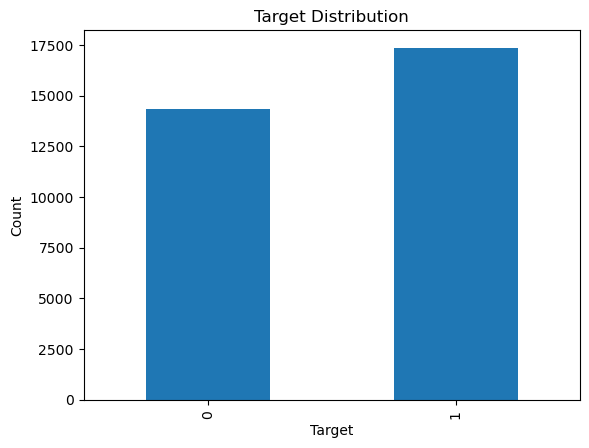


Missing values:
No missing values

Popularity rate by weekday:
weekday
Saturday     0.773927
Sunday       0.700318
Friday       0.563421
Monday       0.518925
Thursday     0.516948
Tuesday      0.506705
Wednesday    0.500334
Name: target, dtype: float64

Popularity rate by channel:
channel
Social Media     0.765485
Tech             0.641839
Other            0.634327
Lifestyle        0.620994
Business         0.529156
Entertainment    0.421955
World            0.407357
Name: target, dtype: float64


In [3]:
# first check the target balance and missing values
print("Target distribution:")
print(train["target"].value_counts())
print("\nTarget proportions:")
print(train["target"].value_counts(normalize=True))

train["target"].value_counts().sort_index().plot(kind="bar")
plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("\nMissing values:")
print("No missing values" if len(missing) == 0 else missing)

print("\nPopularity rate by weekday:")
print(train.groupby("weekday")["target"].mean().sort_values(ascending=False))

print("\nPopularity rate by channel:")
print(train.groupby("channel")["target"].mean().sort_values(ascending=False))


,count,mean,std,min,25%,50%,75%,max
id,31715.0,15857.000000,9155.476230,0.00000,7928.500000,15857.000000,23785.500000,31714.000000
n_tokens_title,31715.0,10.216617,2.059007,2.00000,9.000000,10.000000,12.000000,19.000000
n_tokens_content,31715.0,545.006275,472.320076,0.00000,245.000000,403.000000,706.000000,8474.000000
n_unique_tokens,31715.0,0.564569,3.935137,0.00000,0.476367,0.545455,0.614939,701.000000
n_non_stop_words,31715.0,1.018446,5.846748,0.00000,1.000000,1.000000,1.000000,1042.000000
n_non_stop_unique_tokens,31715.0,0.705974,3.648413,0.00000,0.629921,0.694915,0.759398,650.000000
num_hrefs,31715.0,11.120132,11.250545,0.00000,5.000000,8.000000,14.000000,187.000000
num_self_hrefs,31715.0,3.437080,3.951435,0.00000,1.000000,3.000000,4.000000,74.000000
num_imgs,31715.0,4.734038,8.618716,0.00000,1.000000,1.000000,5.000000,128.000000
num_videos,31715.0,1.260728,4.192666,0.00000,0.000000,0.000000,1.000000,91.000000


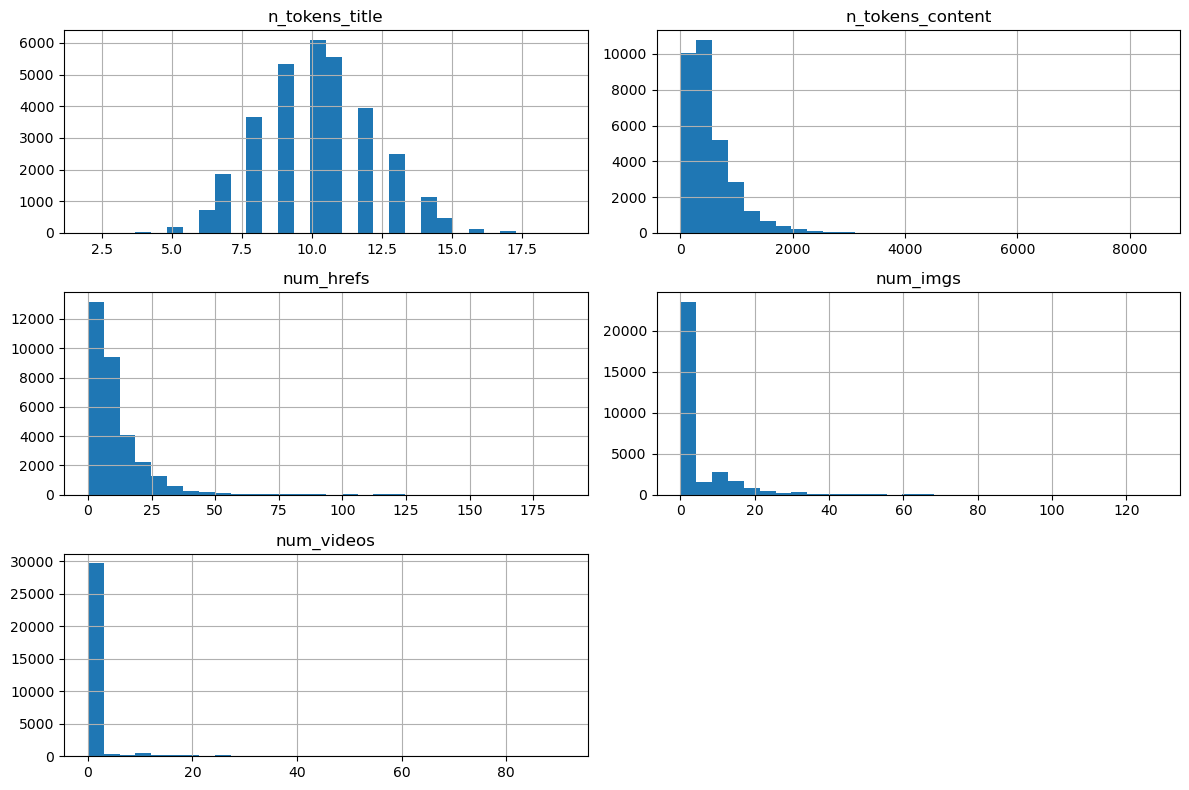

In [4]:
# quick look at the main numerical features
display(train.describe().T)

selected_cols = [
    "n_tokens_title",
    "n_tokens_content",
    "num_hrefs",
    "num_imgs",
    "num_videos"
]

train[selected_cols].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()


In [5]:
# check which numerical features are related or highly correlated
numeric_train = train.select_dtypes(include=["number"])

corr_with_target = (
    numeric_train
    .corr()["target"]
    .drop("target")
    .sort_values(key=abs, ascending=False)
)

print("Top correlations with target:")
print(corr_with_target.head(15))

feature_corr = numeric_train.drop(columns=["target"], errors="ignore").corr().abs()
upper = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr = []

for column in upper.columns:
    for index in upper.index:
        value = upper.loc[index, column]
        if pd.notna(value) and value > 0.85:
            high_corr.append((index, column, value))

high_corr = sorted(high_corr, key=lambda x: x[2], reverse=True)

print("\nHighly correlated pairs:")
for feature_1, feature_2, corr in high_corr[:20]:
    print(f"{feature_1} <-> {feature_2}: {corr:.3f}")

skewness = (
    numeric_train
    .drop(columns=["target"], errors="ignore")
    .skew()
    .sort_values(key=abs, ascending=False)
)

print("\nMost skewed features:")
print(skewness.head(20))


Top correlations with target:
kw_avg_avg                   0.144859
LDA_02                      -0.137853
LDA_04                       0.090937
num_hrefs                    0.086456
kw_min_avg                   0.086404
LDA_01                      -0.081036
global_subjectivity          0.078751
self_reference_avg_shares    0.065904
kw_max_avg                   0.063429
self_reference_max_shares    0.060784
global_sentiment_polarity    0.060327
LDA_00                       0.059566
num_imgs                     0.059272
n_tokens_content             0.055940
self_reference_min_shares    0.055306
Name: target, dtype: float64

Highly correlated pairs:
n_unique_tokens <-> n_non_stop_unique_tokens: 1.000
n_unique_tokens <-> n_non_stop_words: 1.000
n_non_stop_words <-> n_non_stop_unique_tokens: 1.000
kw_max_min <-> kw_avg_min: 0.941
self_reference_max_shares <-> self_reference_avg_shares: 0.861
kw_min_min <-> kw_max_max: 0.851

Most skewed features:
n_non_stop_words             177.976249
n_un

## Data preparation

In [6]:
# sort by date so the validation split follows time order
train["publish_date"] = pd.to_datetime(train["publish_date"])

train = (
    train
    .sort_values(["publish_date", "id"])
    .reset_index(drop=True)
)

print(train["publish_date"].min(), "->", train["publish_date"].max())


2013-01-07 00:00:00 -> 2014-08-28 00:00:00


In [7]:
# create a few simple features from the publication date
def add_date_features(df):
    df = df.copy()

    df["year"] = df["publish_date"].dt.year
    df["month"] = df["publish_date"].dt.month
    df["day"] = df["publish_date"].dt.day
    df["dayofyear"] = df["publish_date"].dt.dayofyear

    reference_date = pd.Timestamp("2013-01-01")
    df["days_since_start"] = (
        df["publish_date"] - reference_date
    ).dt.days

    return df.drop(columns=["publish_date"])


train_model = add_date_features(train)

X = train_model.drop(columns=["target", "id"])
y = train_model["target"]

split_idx = int(len(X) * 0.80)

X_train = X.iloc[:split_idx].copy()
X_valid = X.iloc[split_idx:].copy()

y_train = y.iloc[:split_idx].copy()
y_valid = y.iloc[split_idx:].copy()

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Categorical columns:", categorical_cols)


Training: (25372, 51)
Validation: (6343, 51)
Categorical columns: ['weekday', 'channel']


## Baseline models

In [8]:
# preprocessing for logistic regression
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict_proba(X_valid)[:, 1]
logistic_auc = roc_auc_score(y_valid, logistic_pred)

print("Logistic Regression ROC-AUC:", logistic_auc)


Logistic Regression ROC-AUC: 0.730704736619755


In [9]:
# CatBoost can use categorical columns directly
X_train_cb = X_train.copy()
X_valid_cb = X_valid.copy()

for col in categorical_cols:
    X_train_cb[col] = X_train_cb[col].fillna("missing").astype(str)
    X_valid_cb[col] = X_valid_cb[col].fillna("missing").astype(str)

cat_model = CatBoostClassifier(
    iterations=2000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=5,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=False
)

cat_model.fit(
    X_train_cb,
    y_train,
    cat_features=categorical_cols,
    eval_set=(X_valid_cb, y_valid),
    early_stopping_rounds=150,
    verbose=False
)

cat_pred = cat_model.predict_proba(X_valid_cb)[:, 1]
cat_auc = roc_auc_score(y_valid, cat_pred)

print("CatBoost ROC-AUC:", cat_auc)


CatBoost ROC-AUC: 0.7536968739550985


In [10]:
# LightGBM uses the same train/validation split for a fair comparison
X_train_lgb = X_train.copy()
X_valid_lgb = X_valid.copy()

for col in categorical_cols:
    categories = X[col].dropna().unique()

    X_train_lgb[col] = pd.Categorical(
        X_train_lgb[col],
        categories=categories
    )
    X_valid_lgb[col] = pd.Categorical(
        X_valid_lgb[col],
        categories=categories
    )

lgb_model = LGBMClassifier(
    n_estimators=1500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    verbosity=-1
)

lgb_model.fit(
    X_train_lgb,
    y_train,
    categorical_feature=categorical_cols
)

lgb_pred = lgb_model.predict_proba(X_valid_lgb)[:, 1]
lgb_auc = roc_auc_score(y_valid, lgb_pred)

print("LightGBM ROC-AUC:", lgb_auc)


LightGBM ROC-AUC: 0.7393381506420075


In [11]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "CatBoost",
        "LightGBM"
    ],
    "ROC-AUC": [
        logistic_auc,
        cat_auc,
        lgb_auc
    ]
})

display(
    results.sort_values(
        "ROC-AUC",
        ascending=False
    ).reset_index(drop=True)
)


,Model,ROC-AUC
0,CatBoost,0.753697
1,LightGBM,0.739338
2,Logistic Regression,0.730705


## Feature importance

,Feature,Importance
1,channel,12.165969
0,weekday,8.177739
21,kw_avg_avg,6.331384
22,self_reference_min_shares,5.008947
50,days_since_start,4.917425
49,dayofyear,4.536160
19,kw_min_avg,4.270494
24,self_reference_avg_shares,3.274912
25,LDA_00,3.253590
20,kw_max_avg,2.874623


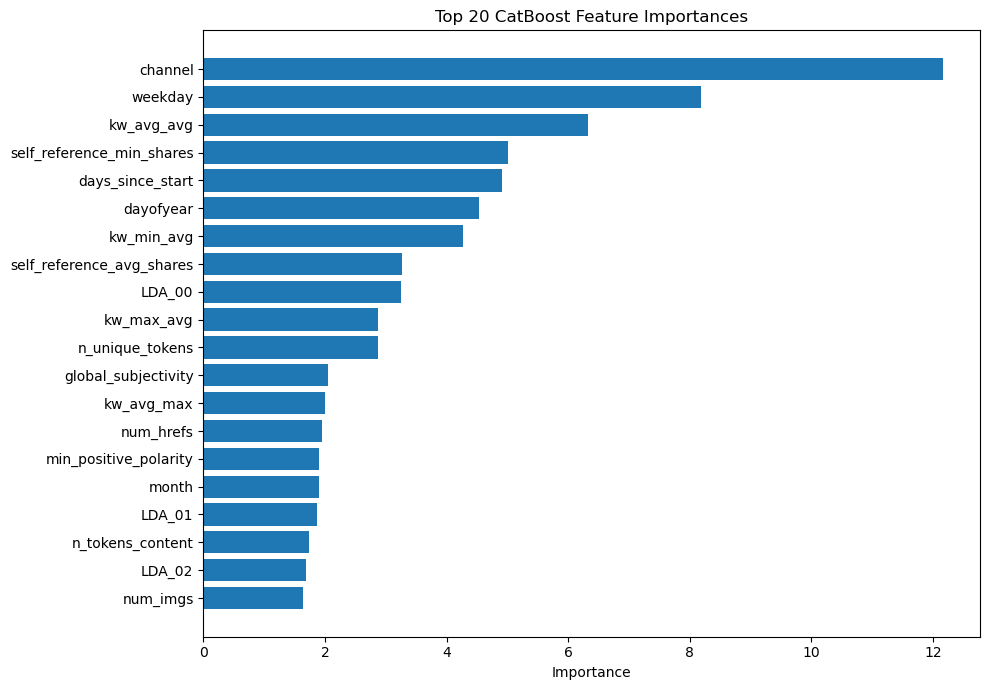

In [12]:
# check which features CatBoost uses the most
feature_importance = pd.DataFrame({
    "Feature": X_train_cb.columns,
    "Importance": cat_model.get_feature_importance()
}).sort_values("Importance", ascending=False)

display(feature_importance.head(20))

top_features = feature_importance.head(20)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)
plt.xlabel("Importance")
plt.title("Top 20 CatBoost Feature Importances")
plt.tight_layout()
plt.show()


## Feature engineering

In [13]:
# add a few ratios and interactions that may carry extra signal
def add_v2_features(df):
    df = df.copy()

    # date
    df["year"] = df["publish_date"].dt.year
    df["month"] = df["publish_date"].dt.month
    df["day"] = df["publish_date"].dt.day
    df["dayofyear"] = df["publish_date"].dt.dayofyear

    reference_date = pd.Timestamp("2013-01-01")
    df["days_since_start"] = (
        df["publish_date"] - reference_date
    ).dt.days

    # content and media
    df["media_count"] = df["num_imgs"] + df["num_videos"]
    df["links_per_token"] = (
        df["num_hrefs"] / (df["n_tokens_content"] + 1)
    )
    df["media_per_token"] = (
        df["media_count"] / (df["n_tokens_content"] + 1)
    )
    df["self_links_ratio"] = (
        df["num_self_hrefs"] / (df["num_hrefs"] + 1)
    )

    # keywords
    df["kw_avg_range"] = df["kw_max_avg"] - df["kw_min_avg"]
    df["kw_avg_mean"] = (
        df["kw_min_avg"] + df["kw_max_avg"]
    ) / 2
    df["kw_min_range"] = df["kw_max_min"] - df["kw_min_min"]

    # self-reference
    df["self_ref_range"] = (
        df["self_reference_max_shares"]
        - df["self_reference_min_shares"]
    )

    # sentiment
    df["sentiment_strength"] = abs(
        df["global_sentiment_polarity"]
    )
    df["title_sentiment_strength"] = abs(
        df["title_sentiment_polarity"]
    )
    df["subjectivity_interaction"] = (
        df["global_subjectivity"]
        * df["title_subjectivity"]
    )

    return df.drop(columns=["publish_date"])


In [14]:
# rebuild the train/validation sets with the engineered features
train_v2 = add_v2_features(train)

X_v2 = train_v2.drop(columns=["target", "id"])
y_v2 = train_v2["target"]

split_idx = int(len(X_v2) * 0.80)

X_train_v2 = X_v2.iloc[:split_idx].copy()
X_valid_v2 = X_v2.iloc[split_idx:].copy()

y_train_v2 = y_v2.iloc[:split_idx].copy()
y_valid_v2 = y_v2.iloc[split_idx:].copy()

categorical_cols_v2 = X_v2.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols_v2:
    X_train_v2[col] = X_train_v2[col].fillna("missing").astype(str)
    X_valid_v2[col] = X_valid_v2[col].fillna("missing").astype(str)

cat_v2 = CatBoostClassifier(
    iterations=2000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=5,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=False
)

cat_v2.fit(
    X_train_v2,
    y_train_v2,
    cat_features=categorical_cols_v2,
    eval_set=(X_valid_v2, y_valid_v2),
    early_stopping_rounds=150,
    verbose=False
)

v2_pred = cat_v2.predict_proba(X_valid_v2)[:, 1]
v2_auc = roc_auc_score(y_valid_v2, v2_pred)

print("Original CatBoost:", cat_auc)
print("With engineered features:", v2_auc)


Original CatBoost: 0.7536968739550985
With engineered features: 0.7564389957733423


In [15]:
# test feature groups separately to see which ones actually help
feature_groups = {
    "content_media": [
        "media_count",
        "links_per_token",
        "media_per_token",
        "self_links_ratio"
    ],
    "keywords": [
        "kw_avg_range",
        "kw_avg_mean",
        "kw_min_range"
    ],
    "self_reference": [
        "self_ref_range"
    ],
    "sentiment": [
        "sentiment_strength",
        "title_sentiment_strength",
        "subjectivity_interaction"
    ]
}

group_results = []

for group_name, new_features in feature_groups.items():
    selected_columns = list(X.columns) + new_features
    X_group = X_v2[selected_columns].copy()

    split_idx = int(len(X_group) * 0.80)

    X_tr = X_group.iloc[:split_idx].copy()
    X_va = X_group.iloc[split_idx:].copy()

    y_tr = y_v2.iloc[:split_idx]
    y_va = y_v2.iloc[split_idx:]

    cat_cols = X_group.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    for col in cat_cols:
        X_tr[col] = X_tr[col].fillna("missing").astype(str)
        X_va[col] = X_va[col].fillna("missing").astype(str)

    model = CatBoostClassifier(
        iterations=2000,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=5,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        verbose=False
    )

    model.fit(
        X_tr,
        y_tr,
        cat_features=cat_cols,
        eval_set=(X_va, y_va),
        early_stopping_rounds=150,
        verbose=False
    )

    pred = model.predict_proba(X_va)[:, 1]
    auc = roc_auc_score(y_va, pred)

    group_results.append({
        "Feature Group": group_name,
        "ROC-AUC": auc,
        "Improvement vs baseline": auc - cat_auc
    })

display(
    pd.DataFrame(group_results)
    .sort_values("ROC-AUC", ascending=False)
    .reset_index(drop=True)
)


,Feature Group,ROC-AUC,Improvement vs baseline
0,content_media,0.755864,0.002167
1,keywords,0.754240,0.000543
2,self_reference,0.753770,0.000073
3,sentiment,0.752922,-0.000774


## CatBoost tuning

In [19]:
# small manual search around the strongest CatBoost settings
configs_v2 = [
    {"depth": 5, "learning_rate": 0.03, "l2_leaf_reg": 5},
    {"depth": 6, "learning_rate": 0.03, "l2_leaf_reg": 5},
    {"depth": 7, "learning_rate": 0.03, "l2_leaf_reg": 5},
    {"depth": 6, "learning_rate": 0.02, "l2_leaf_reg": 7},
    {"depth": 7, "learning_rate": 0.02, "l2_leaf_reg": 7},
]

tuning_results = []

best_auc = -1
best_model = None

for config in configs_v2:
    model = CatBoostClassifier(
        iterations=3000,
        depth=config["depth"],
        learning_rate=config["learning_rate"],
        l2_leaf_reg=config["l2_leaf_reg"],
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        verbose=False
    )

    model.fit(
        X_train_v2,
        y_train_v2,
        cat_features=categorical_cols_v2,
        eval_set=(X_valid_v2, y_valid_v2),
        early_stopping_rounds=150,
        verbose=False
    )

    pred = model.predict_proba(X_valid_v2)[:, 1]
    auc = roc_auc_score(y_valid_v2, pred)

    tuning_results.append({
        **config,
        "best_iteration": model.get_best_iteration(),
        "ROC-AUC": auc
    })

    if auc > best_auc:
        best_auc = auc
        best_model = model

tuning_df = pd.DataFrame(tuning_results).sort_values(
    "ROC-AUC",
    ascending=False
)

display(tuning_df)
print("Best ROC-AUC:", best_auc)


,depth,learning_rate,l2_leaf_reg,best_iteration,ROC-AUC
3,6,0.02,7,1329,0.757232
0,5,0.03,5,512,0.756924
4,7,0.02,7,774,0.756716
1,6,0.03,5,575,0.756439
2,7,0.03,5,736,0.756107


Best ROC-AUC: 0.7572321698511759


## Final model and submission

In [20]:
# retrain the chosen model on all labeled data and create the submission

test = pd.read_csv("data/test.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")

test["publish_date"] = pd.to_datetime(test["publish_date"])

test_v2 = add_v2_features(test)
X_test_v2 = test_v2.drop(columns=["id"])

X_full_v2 = X_v2.copy()

for col in categorical_cols_v2:
    X_full_v2[col] = X_full_v2[col].fillna("missing").astype(str)
    X_test_v2[col] = X_test_v2[col].fillna("missing").astype(str)

assert list(X_full_v2.columns) == list(X_test_v2.columns)

final_model = CatBoostClassifier(
    iterations=1329,
    depth=6,
    learning_rate=0.02,
    l2_leaf_reg=7,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=100
)

final_model.fit(
    X_full_v2,
    y_v2,
    cat_features=categorical_cols_v2
)

test_pred = final_model.predict_proba(X_test_v2)[:, 1]

submission = sample_submission.copy()
submission["target"] = test_pred

submission.to_csv("submission.csv", index=False)

display(submission.head())
print("Shape:", submission.shape)
print("Missing predictions:", submission["target"].isna().sum())

0:	total: 61.9ms	remaining: 1m 22s
100:	total: 15.2s	remaining: 3m 4s
200:	total: 35s	remaining: 3m 16s
300:	total: 56.3s	remaining: 3m 12s
400:	total: 1m 17s	remaining: 3m
500:	total: 1m 37s	remaining: 2m 40s
600:	total: 1m 57s	remaining: 2m 22s
700:	total: 2m 17s	remaining: 2m 2s
800:	total: 2m 31s	remaining: 1m 40s
900:	total: 2m 52s	remaining: 1m 21s
1000:	total: 3m 11s	remaining: 1m 2s
1100:	total: 3m 31s	remaining: 43.8s
1200:	total: 3m 50s	remaining: 24.6s
1300:	total: 4m 9s	remaining: 5.37s
1328:	total: 4m 14s	remaining: 0us


,id,target
0,31715,0.811232
1,31716,0.298062
2,31717,0.718995
3,31718,0.331065
4,31719,0.206754


Shape: (7929, 2)
Missing predictions: 0
